In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10,6)

In [2]:
PROJ_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

ESTACIONES_PATH = PROJ_ROOT / "data" / "interim" / "estaciones.parquet"
VIAJES_PATH = PROJ_ROOT / "data" / "interim" / "viajes_agregados_hora.parquet"

estaciones = pd.read_parquet(ESTACIONES_PATH)
viajes = pd.read_parquet(VIAJES_PATH)

print("Estaciones:", estaciones.shape)
print("Viajes:", viajes.shape)

Estaciones: (480, 5)
Viajes: (3369108, 4)


1. Vista General

In [3]:
display(estaciones.head())

display(viajes.head())

,station_id,name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348824,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667229,-103.365997,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368256,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


,station_id,timestamp,salidas,llegadas
0,2,2023-01-01 09:00:00,0,1
1,2,2023-01-01 12:00:00,1,0
2,2,2023-01-01 13:00:00,1,0
3,2,2023-01-01 15:00:00,3,3
4,2,2023-01-01 16:00:00,1,0


In [4]:
estaciones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   station_id  480 non-null    int16  
 1   name        480 non-null    object 
 2   latitude    480 non-null    float32
 3   longitude   480 non-null    float32
 4   capacity    480 non-null    int16  
dtypes: float32(2), int16(2), object(1)
memory usage: 9.5+ KB


In [5]:
viajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3369108 entries, 0 to 3369107
Data columns (total 4 columns):
 #   Column      Dtype         
---  ------      -----         
 0   station_id  int16         
 1   timestamp   datetime64[ns]
 2   salidas     int16         
 3   llegadas    int16         
dtypes: datetime64[ns](1), int16(3)
memory usage: 45.0 MB


2. Calidad de los datos

In [6]:
pd.DataFrame({
    "Nulos": estaciones.isnull().sum(),
    "%Nulos": round(estaciones.isnull().mean()*100,2)
})

,Nulos,%Nulos
station_id,0,0.0
name,0,0.0
latitude,0,0.0
longitude,0,0.0
capacity,0,0.0


In [7]:
pd.DataFrame({
    "Nulos": viajes.isnull().sum(),
    "%Nulos": round(viajes.isnull().mean()*100,2)
})

,Nulos,%Nulos
station_id,0,0.0
timestamp,0,0.0
salidas,0,0.0
llegadas,0,0.0


In [8]:
print("Duplicados estaciones:", estaciones.duplicated().sum())
print("Duplicados viajes:", viajes.duplicated().sum())

Duplicados estaciones: 0
Duplicados viajes: 0


3. Análisis de estaciones

In [9]:
estaciones.describe()

,station_id,latitude,longitude,capacity
count,480.000000,480.000000,480.000000,480.000000
mean,255.918750,20.678356,-103.361938,17.022917
std,148.356577,0.022007,0.031689,3.843697
min,2.000000,20.636129,-103.433212,11.000000
25%,131.750000,20.664994,-103.384167,15.000000
50%,254.500000,20.674214,-103.362442,15.000000
75%,380.250000,20.688601,-103.339375,19.000000
max,519.000000,20.739523,-103.297112,39.000000


Distribucion de Capacidad

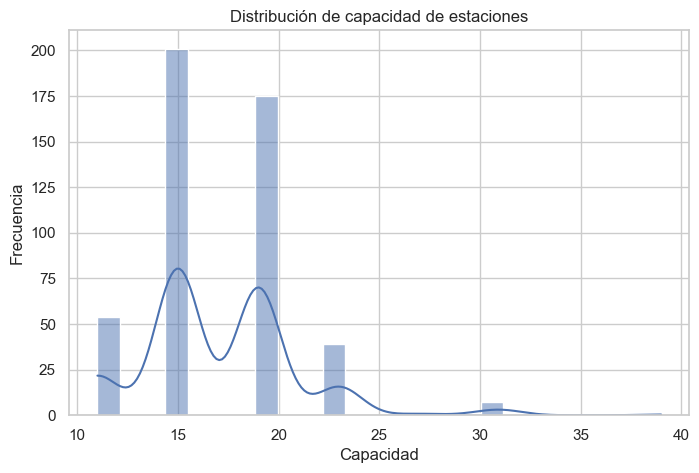

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(
    estaciones["capacity"],
    bins=25,
    kde=True
)

plt.title("Distribución de capacidad de estaciones")
plt.xlabel("Capacidad")
plt.ylabel("Frecuencia")

plt.show()

Gráfica 1. Distribución de capacidad de estaciones
Hallazgo

La distribución de capacidades muestra que las estaciones de MiBici no son homogéneas. Existen estaciones pequeñas, medianas y grandes, lo que indica diferencias importantes en la infraestructura disponible para almacenar bicicletas y anclajes.

Esta variabilidad justifica incorporar la variable capacidad dentro del modelo predictivo, ya que una estación con pocos anclajes tiene mayor probabilidad de saturarse o quedarse sin bicicletas ante cambios relativamente pequeños en la demanda.

Capacidad

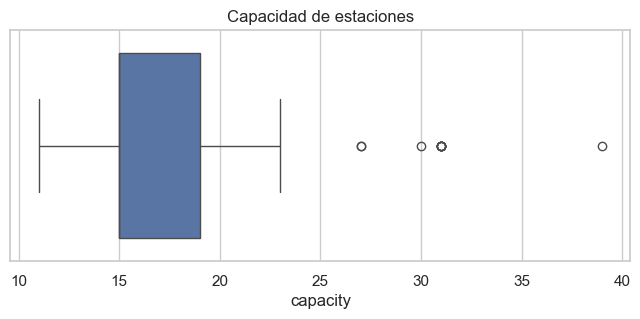

In [12]:
plt.figure(figsize=(8,3))

sns.boxplot(
    x=estaciones["capacity"]
)

plt.title("Capacidad de estaciones")

plt.show()

Gráfica 2. Boxplot de capacidad
Hallazgo

El boxplot permite identificar la dispersión de la capacidad instalada y posibles valores atípicos. Se observa que algunas estaciones poseen una capacidad significativamente superior al promedio del sistema.

Estas diferencias sugieren que no todas las estaciones enfrentan el mismo nivel de riesgo operativo y que las estrategias de rebalanceo deben considerar las características particulares de cada ubicación.


Variables Temporales

In [13]:
viajes["timestamp"] = pd.to_datetime(
    viajes["timestamp"]
)

viajes["hora"] = viajes["timestamp"].dt.hour

viajes["dia_semana"] = viajes["timestamp"].dt.day_name()

viajes["mes"] = viajes["timestamp"].dt.to_period("M")

Demanda por hora

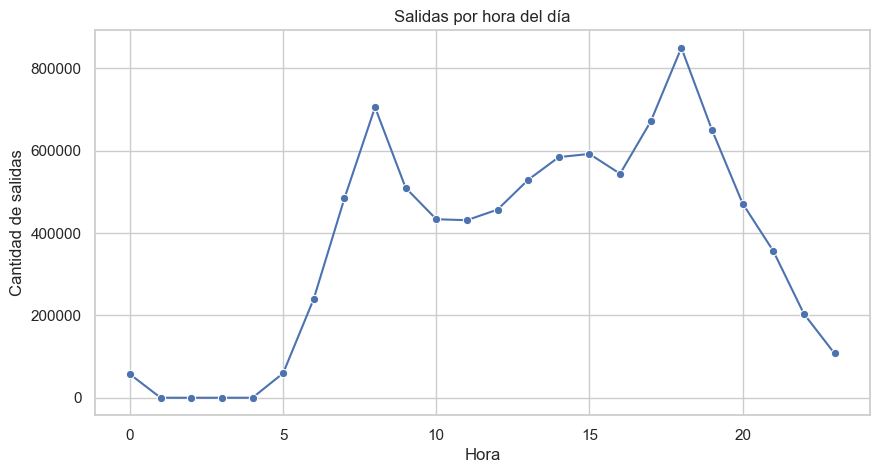

In [14]:
demanda_hora = (
    viajes.groupby("hora")["salidas"]
    .sum()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    x=demanda_hora.index,
    y=demanda_hora.values,
    marker="o"
)

plt.title("Salidas por hora del día")
plt.xlabel("Hora")
plt.ylabel("Cantidad de salidas")

plt.show()

Gráfica 3. Salidas por hora del día
Hallazgo

La demanda de bicicletas presenta un comportamiento claramente dependiente de la hora del día. Se identifican horas de alta actividad y periodos de baja utilización, evidenciando patrones de movilidad recurrentes.

Este comportamiento sugiere la existencia de ciclos diarios asociados a traslados laborales, académicos y actividades cotidianas de los usuarios.



Llegadas por hora

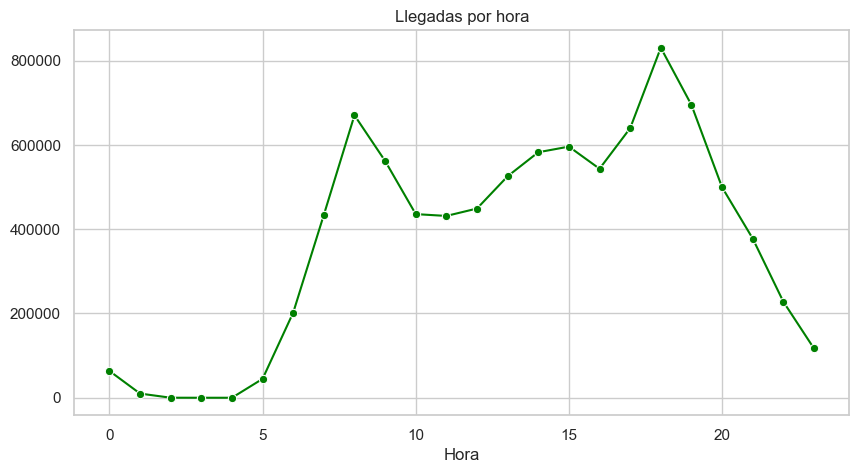

In [15]:
llegadas_hora = (
    viajes.groupby("hora")["llegadas"]
    .sum()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    x=llegadas_hora.index,
    y=llegadas_hora.values,
    marker="o",
    color="green"
)

plt.title("Llegadas por hora")
plt.xlabel("Hora")

plt.show()

Gráfica 4. Llegadas por hora
Hallazgo

Las devoluciones de bicicletas también presentan patrones horarios definidos. En ciertos periodos se observa una concentración importante de llegadas, generando acumulaciones temporales de bicicletas en algunas estaciones.

La similitud entre los patrones de llegadas y salidas sugiere que la operación del sistema sigue ciclos temporales relativamente estables.


Día de la semana

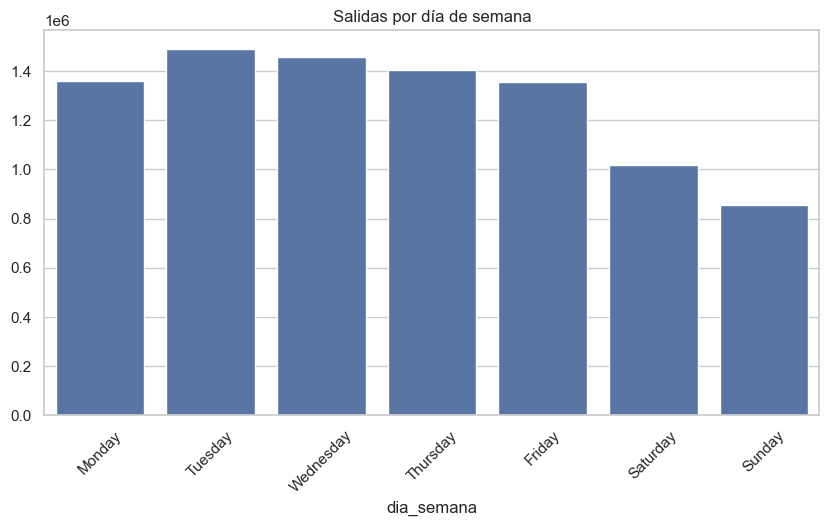

In [16]:
dias = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

tmp = (
    viajes.groupby("dia_semana")["salidas"]
    .sum()
    .reindex(dias)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=tmp.index,
    y=tmp.values
)

plt.xticks(rotation=45)

plt.title("Salidas por día de semana")

plt.show()

Gráfica 5. Salidas por día de la semana
Hallazgo

El volumen de viajes varía entre los diferentes días de la semana. Este comportamiento refleja cambios en los hábitos de movilidad de los usuarios y evidencia diferencias entre días laborales y fines de semana.

La existencia de estas variaciones confirma la presencia de estacionalidad semanal en el sistema.


Estacionalidad mensual

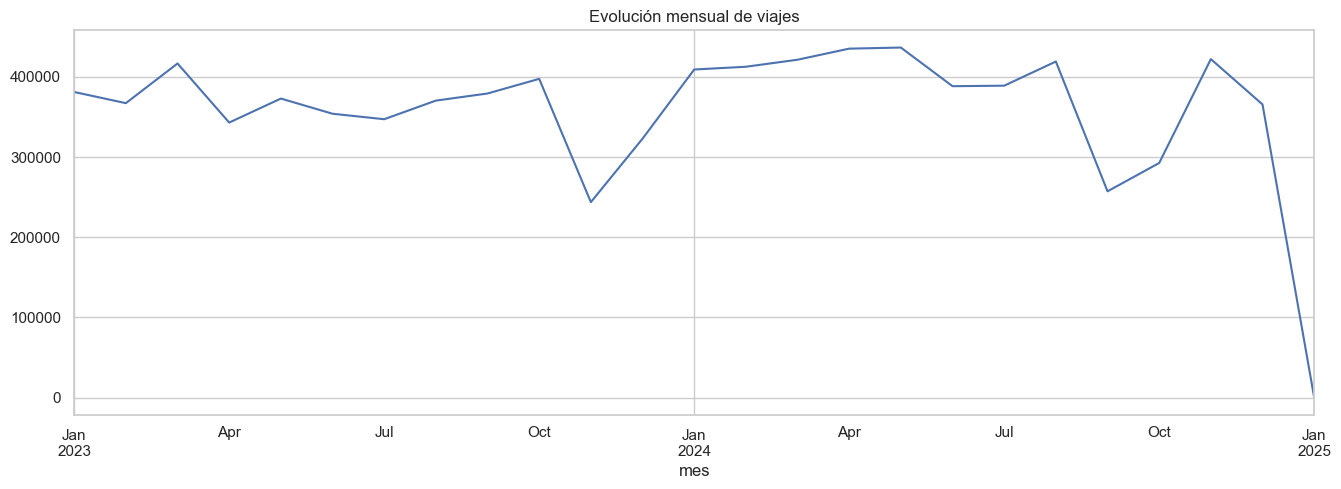

In [17]:
mensual = (
    viajes.groupby("mes")["salidas"]
    .sum()
)

plt.figure(figsize=(16,5))

mensual.plot()

plt.title("Evolución mensual de viajes")

plt.show()

Gráfica 6. Evolución mensual de viajes
Hallazgo

La demanda del sistema presenta fluctuaciones a lo largo del tiempo, mostrando periodos con mayor actividad y otros con menor utilización.

Este comportamiento evidencia la existencia de tendencias y posibles efectos estacionales asociados a factores externos como vacaciones, condiciones climáticas o cambios en el uso del sistema.


Estaciones más usadas

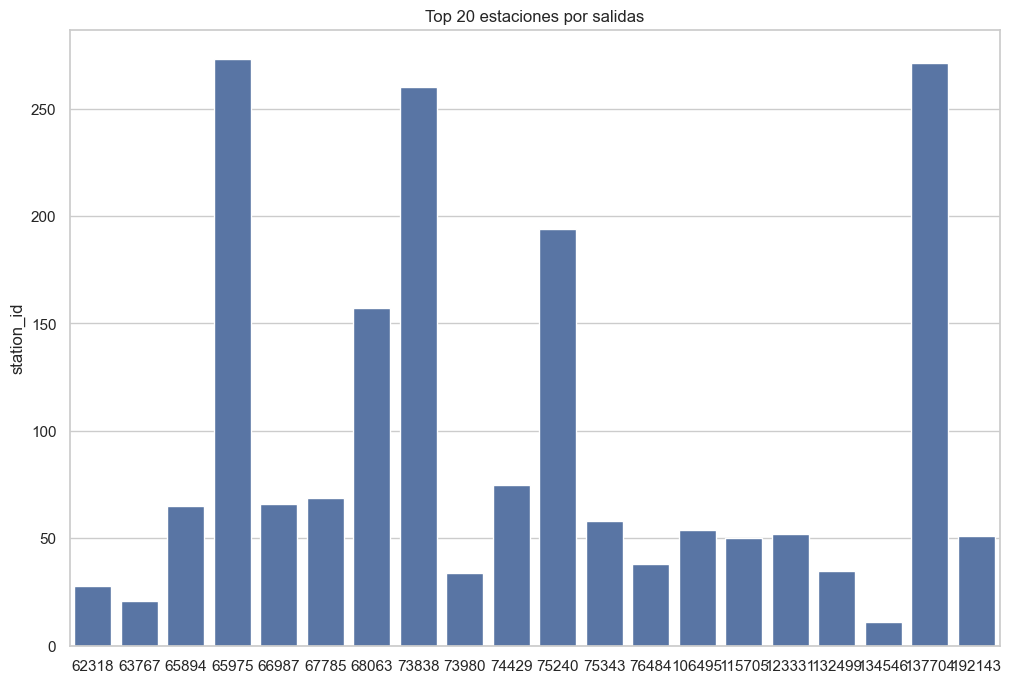

In [18]:
top_estaciones = (
    viajes.groupby("station_id")["salidas"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_estaciones.values,
    y=top_estaciones.index
)

plt.title("Top 20 estaciones por salidas")

plt.show()

Gráfica 7. Top 20 estaciones por salidas
Hallazgo

La demanda no se distribuye de manera uniforme entre las estaciones. Un conjunto relativamente reducido concentra una proporción importante de los viajes realizados.

Esto indica que algunas estaciones actúan como nodos estratégicos dentro de la red de movilidad urbana.


Balance Neto

In [20]:
viajes["balance_neto"] = (
    viajes["llegadas"]
    -
    viajes["salidas"]
)

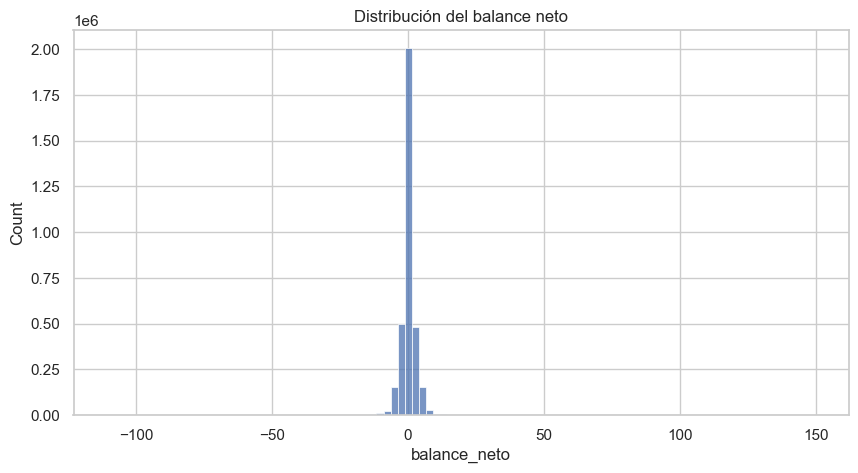

In [21]:
plt.figure(figsize=(10,5))

sns.histplot(
    viajes["balance_neto"],
    bins=100
)

plt.title("Distribución del balance neto")

plt.show()

Gráfica 8. Distribución del balance neto
Hallazgo

La mayoría de los registros presentan balances cercanos a cero, lo que indica una operación relativamente equilibrada entre llegadas y salidas.

Sin embargo, también se observan valores extremos que representan situaciones en las que una estación recibe muchas más bicicletas de las que entrega o viceversa.


Heatmap Hora vs Día

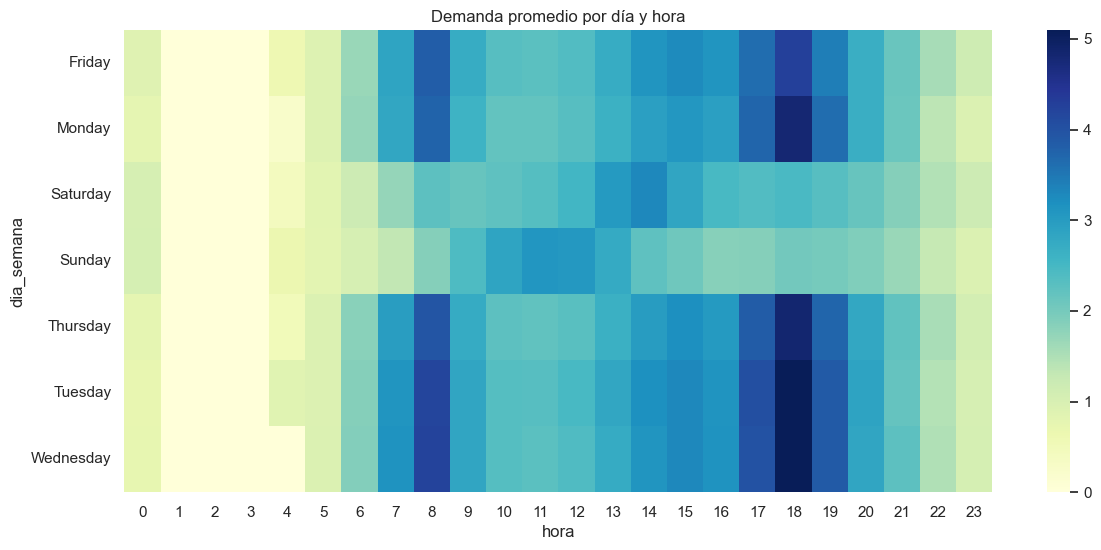

In [22]:
heatmap_data = (
    viajes.groupby(
        ["dia_semana","hora"]
    )["salidas"]
    .mean()
    .unstack()
)

plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu"
)

plt.title(
    "Demanda promedio por día y hora"
)

plt.show()

Gráfica 9. Heatmap de demanda por día y hora
Hallazgo

El mapa de calor permite identificar de manera simultánea patrones horarios y semanales. Determinadas combinaciones de día y hora concentran una demanda significativamente superior al promedio.

La visualización confirma que la utilización del sistema depende tanto del momento del día como del contexto semanal.

Capacidad vs Demanda

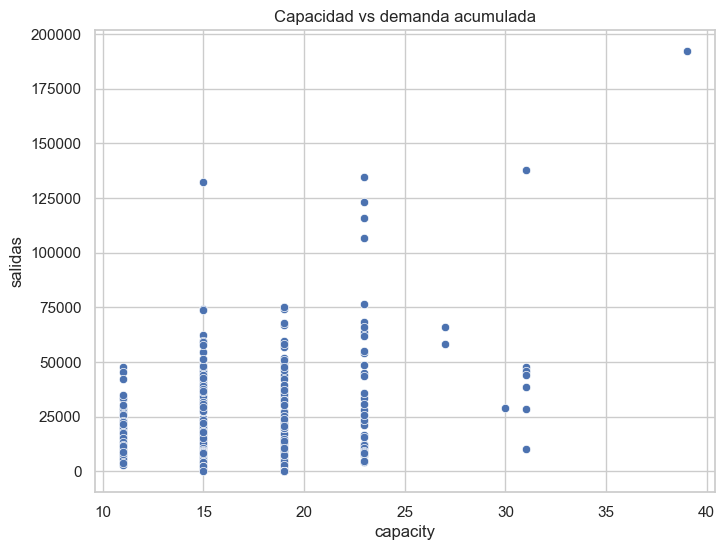

In [23]:
demanda_total = (
    viajes.groupby("station_id")
    .agg({"salidas":"sum"})
    .reset_index()
)

df_plot = estaciones.merge(
    demanda_total,
    on="station_id"
)

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_plot,
    x="capacity",
    y="salidas"
)

plt.title(
    "Capacidad vs demanda acumulada"
)

plt.show()

Gráfica 10. Capacidad vs Demanda Acumulada
Hallazgo

Se aprecia una relación entre la infraestructura disponible y el nivel de utilización de las estaciones. En general, las estaciones con mayor capacidad tienden a registrar volúmenes más altos de actividad.

No obstante, también existen excepciones que sugieren la influencia de factores adicionales como ubicación geográfica, conectividad o atractivo de la zona.

Mapa de estaciones (muy fuerte para la rúbrica)

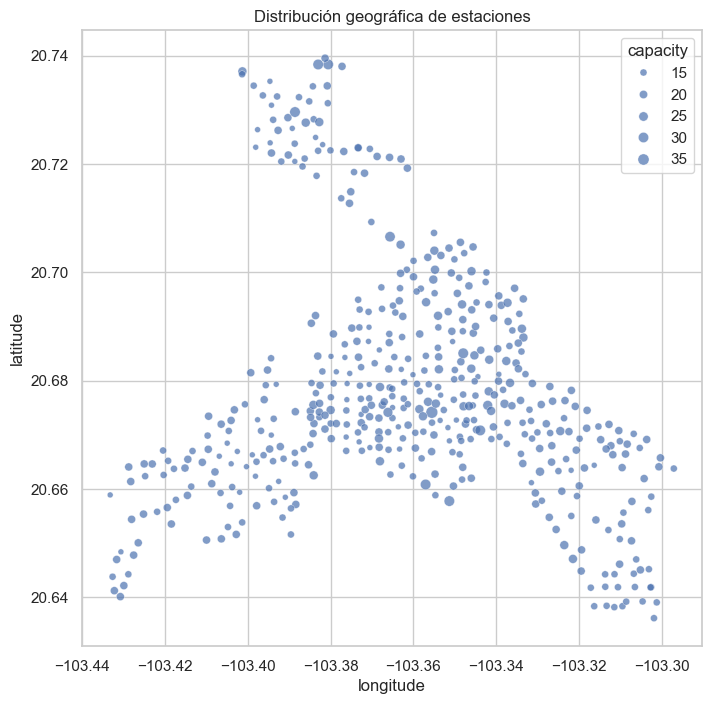

In [24]:
plt.figure(figsize=(8,8))

sns.scatterplot(
    data=estaciones,
    x="longitude",
    y="latitude",
    size="capacity",
    alpha=0.7
)

plt.title(
    "Distribución geográfica de estaciones"
)

plt.show()

Gráfica 11. Distribución geográfica de estaciones
Hallazgo

Las estaciones muestran una distribución espacial concentrada en determinadas zonas urbanas. Algunas áreas presentan una mayor densidad de infraestructura y capacidad instalada que otras.

Esta concentración espacial refleja la estrategia de despliegue del sistema de bicicletas públicas.

Ranking de estaciones con mayor riesgo potencial

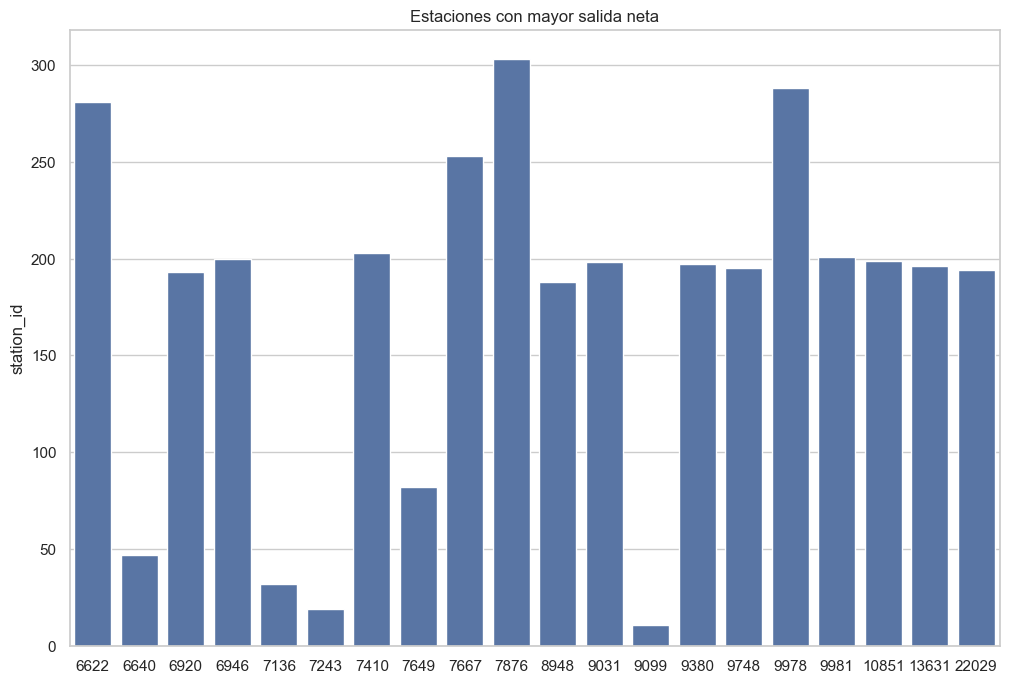

In [25]:
riesgo = (
    viajes.groupby("station_id")
    .agg({
        "salidas":"sum",
        "llegadas":"sum"
    })
)

riesgo["diferencia"] = (
    riesgo["salidas"]
    -
    riesgo["llegadas"]
)

top_riesgo = (
    riesgo["diferencia"]
    .sort_values(
        ascending=False
    )
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_riesgo.values,
    y=top_riesgo.index
)

plt.title(
    "Estaciones con mayor salida neta"
)

plt.show()

Gráfica 12. Estaciones con mayor salida neta
Hallazgo

Las estaciones con salida neta positiva extraen más bicicletas de las que reciben, generando una tendencia natural al vaciamiento.

Estas ubicaciones representan puntos críticos desde la perspectiva operativa, ya que requieren intervenciones de rebalanceo para mantener la disponibilidad del servicio.

Resumen

El análisis exploratorio permitió identificar patrones espaciales, temporales y operativos relevantes dentro del sistema MiBici. Se observaron diferencias significativas en la capacidad de las estaciones, variaciones de demanda según la hora del día y el día de la semana, así como estaciones con comportamientos persistentemente desbalanceados. Estos hallazgos respaldan la selección de variables históricas de demanda y oferta, características temporales cíclicas y atributos geoespaciales utilizados posteriormente en el proceso de ingeniería de características y en el modelo de clasificación para la detección temprana de riesgo de desabasto o saturación de estaciones.